# Sieci neuronowe 1 - LAB

    prowadzący: Monika Wasilewska
    Politechnika Wrocławska, Katedra Akustyki, Multimediów i Przetwarzania Sygnałów
    

Run a cell via `Shift + Return`. Learn more about [CoCalc Jupyter Notebooks](https://doc.cocalc.com/jupyter.html).

---
Plan zajęć:
---

1. Wczytywanie i wyświetlanie obrazów.
2. Wstępne przetwarzanie i analiza:
    - analiza histogramów, 
    - obrót obrazu,
    - normalizacja,
    - wyrównanie histogramu,
    - różne metody przejścia do skali szarości.|
3. Wektoryzacja danych.
4. Kodowanie "one-hot", konwersja etykiet.
5. Inne typy daych - wczytanie dodatkowej bazy. Analiza wartości, normalizacja.
---

## Zadanie 1

Wczytaj obrazek dołączony do katalogu Lab_1, a następnie go wyświetl, wykorzystaj do tego metodę `imread()` oraz `imshow()`. Sprawdź jgo rozmiar. 

[[[ 12   4   2]
  [ 12   4   2]
  [ 12   4   2]
  ...
  [  8  13  16]
  [  8  13  16]
  [  8  13  16]]

 [[ 12   4   2]
  [ 12   4   2]
  [ 12   4   2]
  ...
  [  8  13  16]
  [  8  13  16]
  [  8  13  16]]

 [[ 12   4   2]
  [ 12   4   2]
  [ 12   4   2]
  ...
  [  8  13  16]
  [  8  13  16]
  [  8  13  16]]

 ...

 [[112  87  83]
  [112  87  83]
  [112  87  83]
  ...
  [168 135 130]
  [168 135 130]
  [169 136 131]]

 [[109  85  81]
  [109  85  81]
  [108  84  80]
  ...
  [166 131 125]
  [166 131 125]
  [166 131 125]]

 [[108  84  80]
  [108  84  80]
  [107  83  79]
  ...
  [166 131 125]
  [166 131 125]
  [166 131 125]]]


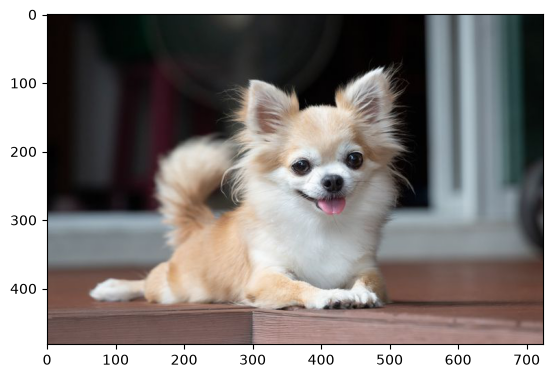

In [3]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import numpy as np

dog = plt.imread("minidog.jpg")
plt.imshow(dog)
x = np.array(dog)
print(x)

Rozmiar obrazka to: `... x ... x ... x`, co oznacza:  `wysokość/szerokość/liczba kanałów x wysokość/szerokość/liczba kanałów x wysokość/szerokość/liczba kanałów`

# Zadanie 2
Nasz obrazek ma 3 kanały. Każdy z nich odpowiada za jedną ze skaładowych. Korzystając z `subplot` z pakietu `matplotlib` wyrysuj każdą ze składowych oddzielnie.
Opcja: wybierz odpowiednią paletę barw do każdego z nich.

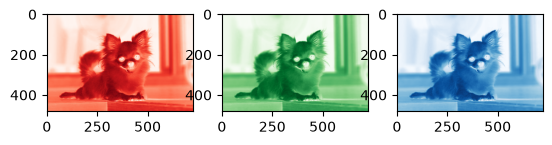

In [4]:
plt.subplot(1, 3, 1)
red = plt.imshow(dog[:,:,0], "Reds")
plt.subplot(1, 3, 2)
green = plt.imshow(dog[:,:,0], "Greens")
plt.subplot(1, 3, 3)
blue = plt.imshow(dog[:,:,0], "Blues")

## Zadanie 3

Napisz dwie funkcje, które pozwolą na przeniesienie kolorowego obrazka do sklai szarości. W pierwszej niech kazdy kolor będzie równie istotny, w drugiej proporcje niech wynoszą: $x = 0.299R + 0.587G + 0.114B$. Przetestuj na wcześniej wczytanym obrazku, wyświetl rezultaty i porównaj efekt. 

In [5]:
def funkcja1(dog):
    r, g, b = dog[:,:,0], dog[:,:,1], dog[:,:,2]
    x = 0.33 * r + 0.33 * g + 33 * b
    return x

In [6]:
def funkcja2(rgb):
    r, g, b = dog[:,:,0], dog[:,:,1], dog[:,:,2]
    x = 0.2989 * r + 0.5870 * g + 0.1140 * b
    return x

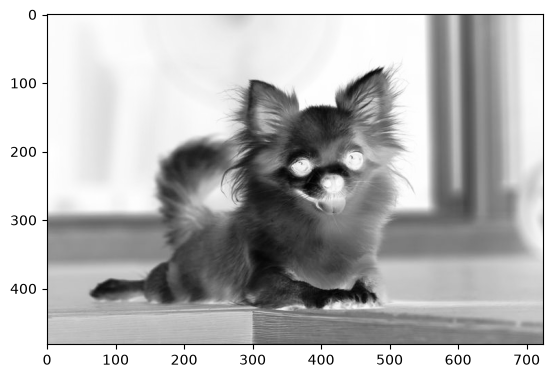

In [7]:
gr1 = funkcja1(dog)
plt.imshow(funkcja1(dog), "Grays")
gr2 = funkcja2(dog)
plt.imshow(funkcja2(dog), "Grays")

## Zadanie 4

Napisz funkcję, która pozwoli na normalizację przekazanego obrazka. Przetestuj ją na wczytanym obrazku oraz tym w skali szarości.

In [9]:
def norm(img):
    x = img / 255
    return x

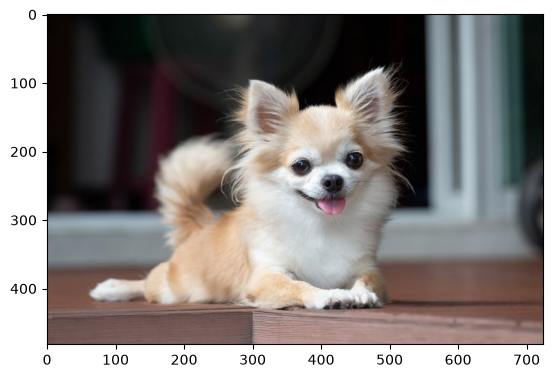

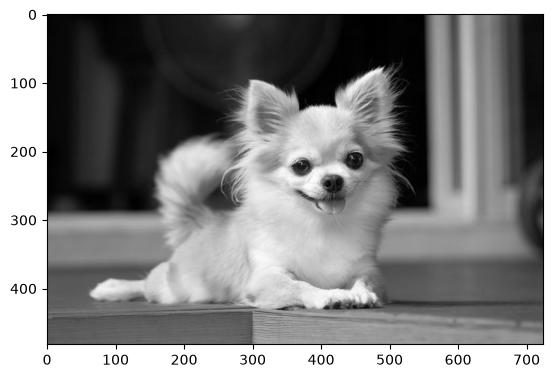

In [10]:
plt.imshow(norm(dog))
plt.show()

plt.imshow(norm(gr2), cmap="gray")
plt.show()

## Zadanie 5
Narysuj histogram dla każdej z barw pierwotnie wczytanego obrazka. Czy rozkłady sa równomierne?

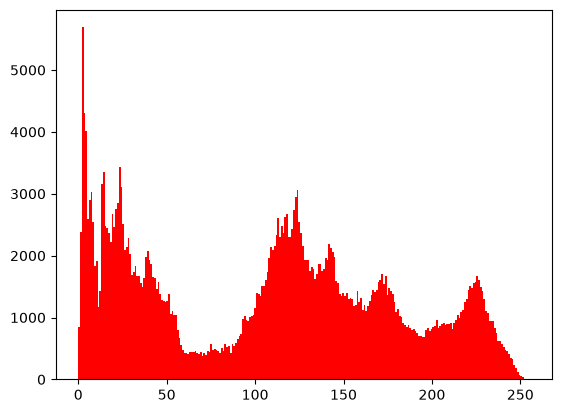

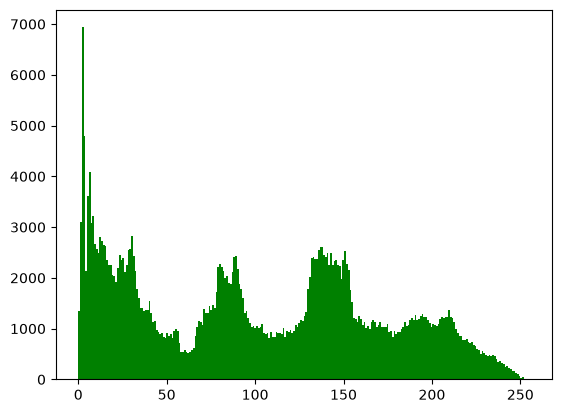

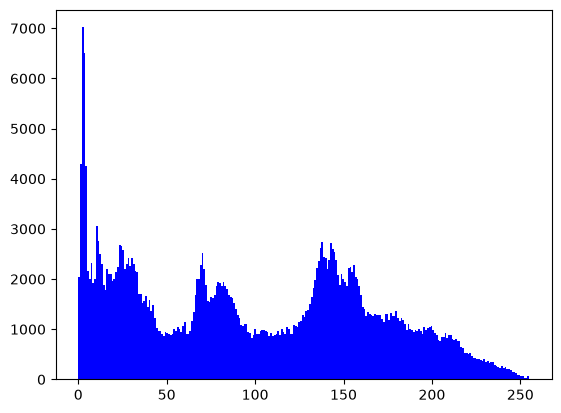

In [11]:
plt.hist(dog[:,:,0].ravel(), bins=256, color="red")
plt.show()

plt.hist(dog[:,:,1].ravel(), bins=256, color="green")
plt.show()

plt.hist(dog[:,:,2].ravel(), bins=256, color="blue")
plt.show()

In [12]:
Nie, rozkłady nie są równomierne, ponieważ wartości pikseli skupiają się w określonych zakresach jasności.

<class 'SyntaxError'>: invalid syntax (3349779837.py, line 1)

## Zadanie 6 (`*`)
Sprawdź w jaki sposób wyrównać histogram. Przeanalizuj nowe wyglady histogramów. Kiedy ta operacja może być szczególnie potrzebna?


## Zadanie 7
Za pomocą metody `rotate` z `scipy.ndimage` obróć obrazek. Sprawdź dokumentację, co będzie efektem działania? (Oryginany zmieniony obrazek, kopia obrazka, czy zostanie coś zwrócone)

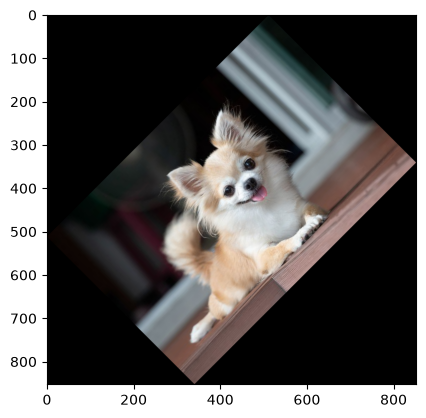

In [17]:
import scipy.ndimage as ndimage

obrot = ndimage.rotate(dog, 45)

plt.imshow(obrot)
plt.show()

# Zadanie 8
Wejście do sieci MLP jest jednowymiarowe, wobec czego musimy "spłaszczyć" nasz obrazek. Napisz funkcję która zwróci zwektoryzowany obrazek. Przetestuj czy działa poprawnie.

In [21]:
def wektoryzacja(img):
    return img.flatten()

# Test
dog_vec = wektoryzacja(dog)

print(dog_vec)
print(dog_vec.shape)

[ 12   4   2 ... 166 131 125]
(1046904,)


## Zadanie 9

Napisz metodę, która zamieni standardowe wartości etykiet na tzw. "one-hot". Przetestuj ją dla list etykiet podanych poniżej. Pamiętaj, że metoda ma działać dla dowolnej wielkości zbioru wartości etykiet.
Przykład dla 3 klas:

```Etykieta    kodowanie```

        0      1 0 0
        
        1      0 1 0
        
        2      0 0 1 

In [25]:
labels_list_0 = [1,0,2,5,3,4]
labels_list_1 = [1,1,2,1]
labels_list_2 = [1,0,9,2,7,5,6,3,8,4]


def one_hot(labels):
    liczba_klas = max(labels) + 1
    wynik = np.zeros((len(labels), liczba_klas), dtype=int)

    for i, label in enumerate(labels):
        wynik[i][label] = 1

    return wynik

print(one_hot(labels_list_0))
print(one_hot(labels_list_1))
print(one_hot(labels_list_2))


[[0 1 0 0 0 0]
 [1 0 0 0 0 0]
 [0 0 1 0 0 0]
 [0 0 0 0 0 1]
 [0 0 0 1 0 0]
 [0 0 0 0 1 0]]
[[0 1 0]
 [0 1 0]
 [0 0 1]
 [0 1 0]]
[[0 1 0 0 0 0 0 0 0 0]
 [1 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 1]
 [0 0 1 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 1 0 0]
 [0 0 0 0 0 1 0 0 0 0]
 [0 0 0 0 0 0 1 0 0 0]
 [0 0 0 1 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 1 0]
 [0 0 0 0 1 0 0 0 0 0]]


---